In [11]:
# import os
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import time
import copy

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import joblib

import torch
import torch.nn as nn

from utils import get_opt, get_loaders, eval_ppl
from predictor_definitions import LogisticRegression, MLPClassifier

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
layers_to_keep = (0, 1, 23)

# Loading

## Model

In [3]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
# model_name = "HuggingFaceTB/SmolLM2-360M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Predictors

In [4]:
for i, layer in enumerate(model.model.layers):
    if i in layers_to_keep: 
        continue
    layer.predictor = {}
    layer.predictor['lr'] = joblib.load(f'predictors/cls_model_layer{i}.pkl')
    layer.predictor['nn'] = joblib.load(f'predictors/cls_model_mlp_layer{i}.pkl')

### Alternative (rel L1)

In [4]:
for i, layer in enumerate(model.model.layers):
    if i in layers_to_keep: 
        continue
    layer.predictor = {}
    layer.predictor['alt_lr'] = joblib.load(f'predictors_rel_L1/cls_model_layer{i}.pkl')

## Data

In [5]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


# Router

In [6]:
class MLPRouter(nn.Module):
    def __init__(self, predictor, mlp, save_bitmap=False):
        super().__init__()
        self.predictor = predictor
        self.mlp = mlp
        self.n_total = 0
        self.n_mlp = 0
        self.save_bitmap = save_bitmap
        if save_bitmap:
            self.bitmap = []
        
    def forward(self, x):
        use_mlp = self.predictor.predict(x.to(torch.float)).astype(bool)
        # print(use_mlp.flatten().sum())
        bsz, seq_len, dim = x.shape
        x_flat = x.view(-1, dim)
        use_mlp_flat = use_mlp.flatten()  # shape: (bsz * seq_len)
        self.n_mlp += use_mlp_flat.sum()
        self.n_total += use_mlp_flat.size
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if use_mlp_flat.any():
            selected = x_flat[use_mlp_flat]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[use_mlp_flat] = mlp_out      # insert results
            if self.save_bitmap:
                self.bitmap.extend(use_mlp_flat.tolist())

        return out.view(bsz, seq_len, dim)
        

# Evaluate pruned model

In [15]:
def eval_model(use_router='', results_router=None, layer_stats=None, auc_thr=-1, AUC_data='prediction_results.csv', save_bitmap=False):
    if layer_stats is None:
        layer_stats = pd.DataFrame()
    if results_router is None:
        results_router = pd.DataFrame(columns=["perplexity", "del_ratio", "inference_time"])

    if use_router:
        predictor_quality = pd.read_csv(AUC_data, index_col=0)
        auc_col = 'AUC' if 'lr' in use_router else 'AUC_mlp'
        
        # replace MLP with router only if the AUC is high enough for the layer
        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep or predictor_quality.loc[i, auc_col] < auc_thr:
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = MLPRouter(predictor, mlp_copy, save_bitmap=save_bitmap)
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0

    global_skip_ratio = 0
    routing_bitmap = []
    
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep or predictor_quality.loc[i, auc_col] < auc_thr:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped
            
            if save_bitmap:
                routing_bitmap.append(layer.mlp.bitmap)

            layer_stats.at[i, column_name] = skip_ratio
            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
        layer_stats.at['all', column_name] = global_skip_ratio
    
    results_router.loc[use_router] = [ppl, global_skip_ratio, t]
    return {'results_router': results_router, 'layer_stats': layer_stats, 'routing_bitmap': routing_bitmap}

In [15]:
results_dict = eval_model('lr', save_bitmap=True)
bitmap_lr = results_dict['routing_bitmap']
results_dict = eval_model('nn', results_router=results_dict['results_router'], layer_stats=results_dict['layer_stats'], save_bitmap=True)
bitmap_mlp = results_dict['routing_bitmap']
results_dict = eval_model('', results_router=results_dict['results_router'], layer_stats=results_dict['layer_stats'], save_bitmap=True)
results_dict['results_router'].to_csv('results_router.csv')
results_dict['results_router']

,perplexity,del_ratio,inference_time
lr,72.759705,0.259735,8.755876
nn,2511.279053,0.338488,8.454461
,7.260689,0.000000,9.264641


## Visualization of routing

In [16]:
pd.DataFrame(bitmap_lr).to_csv('bitmap_lr.csv')
pd.DataFrame(bitmap_mlp).to_csv('bitmap_mlp.csv')

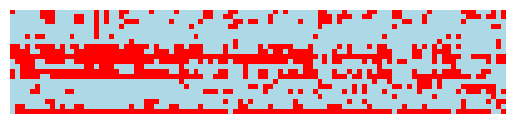

In [17]:
# bitmap of routing using LR
bitmap_lr_slice = [row[:100] for row in bitmap_lr]
cmap = ListedColormap(["red", "lightblue"])  # skipped=red
plt.imshow(bitmap_lr_slice, cmap=cmap, interpolation="nearest")
plt.axis("off")
plt.show()

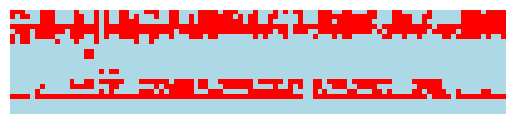

In [18]:
# bitmap of routing using MLP
bitmap_mlp_slice = [row[:100] for row in bitmap_mlp]
cmap = ListedColormap(["red", "lightblue"])  # skipped=red
plt.imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
plt.axis("off")
plt.show()

## Ratio of tokens routed around the MLP

In [11]:
results_dict['layer_stats']

,lr,nn
2,0.424930,0.593971
3,0.404970,0.615884
4,0.181083,0.467295
5,0.103595,0.946269
6,0.000092,0.893377
7,0.032893,0.226226
8,0.028436,0.392149
9,0.094769,0.056895
10,0.202680,0.054872
11,0.524378,0.032708


# Eval pruned model using only predictors with AUC > thr

In [19]:
results_thr_dict = eval_model('lr', auc_thr=0.8)
results_thr_dict = eval_model('nn', results_router=results_thr_dict['results_router'], layer_stats=results_thr_dict['layer_stats'], auc_thr=0.8)
results_thr_dict = eval_model('', results_router=results_thr_dict['results_router'], layer_stats=results_thr_dict['layer_stats'], auc_thr=0.8)
results_thr_dict['results_router'].to_csv('results_router_thr.csv')
results_thr_dict['results_router']

,perplexity,del_ratio,inference_time
lr,26.699060,0.144735,9.028778
nn,1856.006836,0.311715,8.486077
,7.260689,0.000000,9.314116


In [20]:
results_thr_dict['layer_stats']

,lr,nn
2,0.424930,0.593971
3,0.404970,0.615884
4,0.181083,0.467295
5,0.103595,0.946269
6,0.000092,0.893377
7,0.032893,0.226226
8,0.028436,0.392149
9,0.094769,0.056895
10,0.202680,0.054872
11,0.524378,0.032708


---
# Top-k router

In [35]:
class MLPRouterTopK(nn.Module):
    def __init__(self, predictor, mlp, k=0.7):
        super().__init__()
        self.predictor = predictor
        self.mlp = mlp
        self.k = k
        self.n_total = 0
        self.n_mlp = 0
        
    def forward(self, x):
        # compute logits
        use_mlp_probs = torch.Tensor(self.predictor.predict_proba(x.to(torch.float)))
        bsz, seq_len, dim = x.shape
        x_flat = x.view(-1, dim)

        k_per_row = max(1, int(seq_len * self.k))  # ensure at least 1
        selected_idx = torch.topk(use_mlp_probs, k_per_row, dim=1).indices.flatten()  # (bsz, k_per_row)
        
        self.n_mlp += selected_idx.numel()
        self.n_total += use_mlp_probs.numel()
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if selected_idx.numel():
            selected = x_flat[selected_idx]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[selected_idx] = mlp_out      # insert results

        return out.view(bsz, seq_len, dim)
        

In [46]:
def eval_model_topk(use_router='', results_router=None, layer_stats=None, k=0.7):
    if layer_stats is None:
        layer_stats = pd.DataFrame()
    if results_router is None:
        results_router = pd.DataFrame(columns=["perplexity", "del_ratio", "inference_time"])

    if use_router:
        predictor_quality = pd.read_csv('prediction_results.csv', index_col=0)
        auc_col = 'AUC' if use_router == 'lr' else 'AUC_mlp'
        
        # replace MLP with router only if the AUC is high enough for the layer
        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = MLPRouterTopK(predictor, mlp_copy, k=k)
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0

    global_skip_ratio = 0
    # repair
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped

            layer_stats.at[i, column_name] = skip_ratio
            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
        layer_stats.at['all', column_name] = global_skip_ratio
    
    results_router.loc[use_router] = [ppl, global_skip_ratio, t]
    return results_router, layer_stats

In [47]:
results_router_top70 = pd.DataFrame(columns=["perplexity", "del_ratio", "inference_time"])

results_router_top70, layer_stats_top70 = eval_model_topk('lr', results_router=results_router_top70)
results_router_top70, layer_stats_top70 = eval_model_topk('nn', results_router=results_router_top70, layer_stats=layer_stats_top70)
results_router_top70, layer_stats_top70 = eval_model_topk('', results_router=results_router_top70, layer_stats=layer_stats_top70)
results_router_top70.to_csv('results_router_top70.csv')
results_router_top70

,perplexity,del_ratio,inference_time
lr,1039.368042,0.262543,9.091006
nn,1289.151855,0.262543,9.168533
,7.260689,0.000000,9.432903


In [48]:
layer_stats_top70

,lr,nn
2,0.300049,0.300049
3,0.300049,0.300049
4,0.300049,0.300049
5,0.300049,0.300049
6,0.300049,0.300049
7,0.300049,0.300049
8,0.300049,0.300049
9,0.300049,0.300049
10,0.300049,0.300049
11,0.300049,0.300049


In [44]:
results_router_top80 = pd.DataFrame(columns=["perplexity", "del_ratio", "inference_time"])

results_router_top80, layer_stats_top80 = eval_model_topk('lr', results_router=results_router_top80, k=0.8)
results_router_top80, layer_stats_top80 = eval_model_topk('nn', results_router=results_router_top80, layer_stats=layer_stats_top80, k=0.8)
results_router_top80, layer_stats_top80 = eval_model_topk('', results_router=results_router_top80, layer_stats=layer_stats_top80, k=0.8)
results_router_top80.to_csv('results_router_top80.csv')
results_router_top80

,perplexity,del_ratio,inference_time
lr,221.014053,0.175064,9.332561
nn,37.842999,0.175064,9.385179
,7.260689,0.000000,9.347976


In [45]:
layer_stats_top80

,lr,nn
2,0.200073,0.200073
3,0.200073,0.200073
4,0.200073,0.200073
5,0.200073,0.200073
6,0.200073,0.200073
7,0.200073,0.200073
8,0.200073,0.200073
9,0.200073,0.200073
10,0.200073,0.200073
11,0.200073,0.200073


# Alternative rel_L1 approach

In [10]:
results_dict = eval_model('alt_lr', save_bitmap=True)
bitmap_lr_alt = results_dict['routing_bitmap']
results_dict = eval_model('', results_router=results_dict['results_router'], layer_stats=results_dict['layer_stats'], save_bitmap=True)
results_dict['results_router'].to_csv('results_alt_router.csv')
results_dict['results_router']

,perplexity,del_ratio,inference_time
alt_lr,21.553188,0.216431,9.974792
,7.260689,0.000000,9.182768


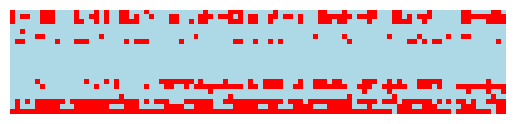

In [12]:
# bitmap of routing using LR
bitmap_lr_slice = [row[:100] for row in bitmap_lr_alt]
cmap = ListedColormap(["red", "lightblue"])  # skipped=red
plt.imshow(bitmap_lr_slice, cmap=cmap, interpolation="nearest")
plt.axis("off")
plt.show()

In [16]:
results_thr_dict = eval_model('alt_lr', auc_thr=0.8, AUC_data='prediction_results_rel_L1.csv', save_bitmap=True)
bitmap_lr_alt = results_thr_dict['routing_bitmap']
results_thr_dict = eval_model('', results_router=results_thr_dict['results_router'], layer_stats=results_thr_dict['layer_stats'])
results_thr_dict['results_router'].to_csv('results_alt_router_thr.csv')
results_thr_dict['results_router']

,perplexity,del_ratio,inference_time
alt_lr,12.172211,0.107895,9.055032
,7.260689,0.000000,9.192427
